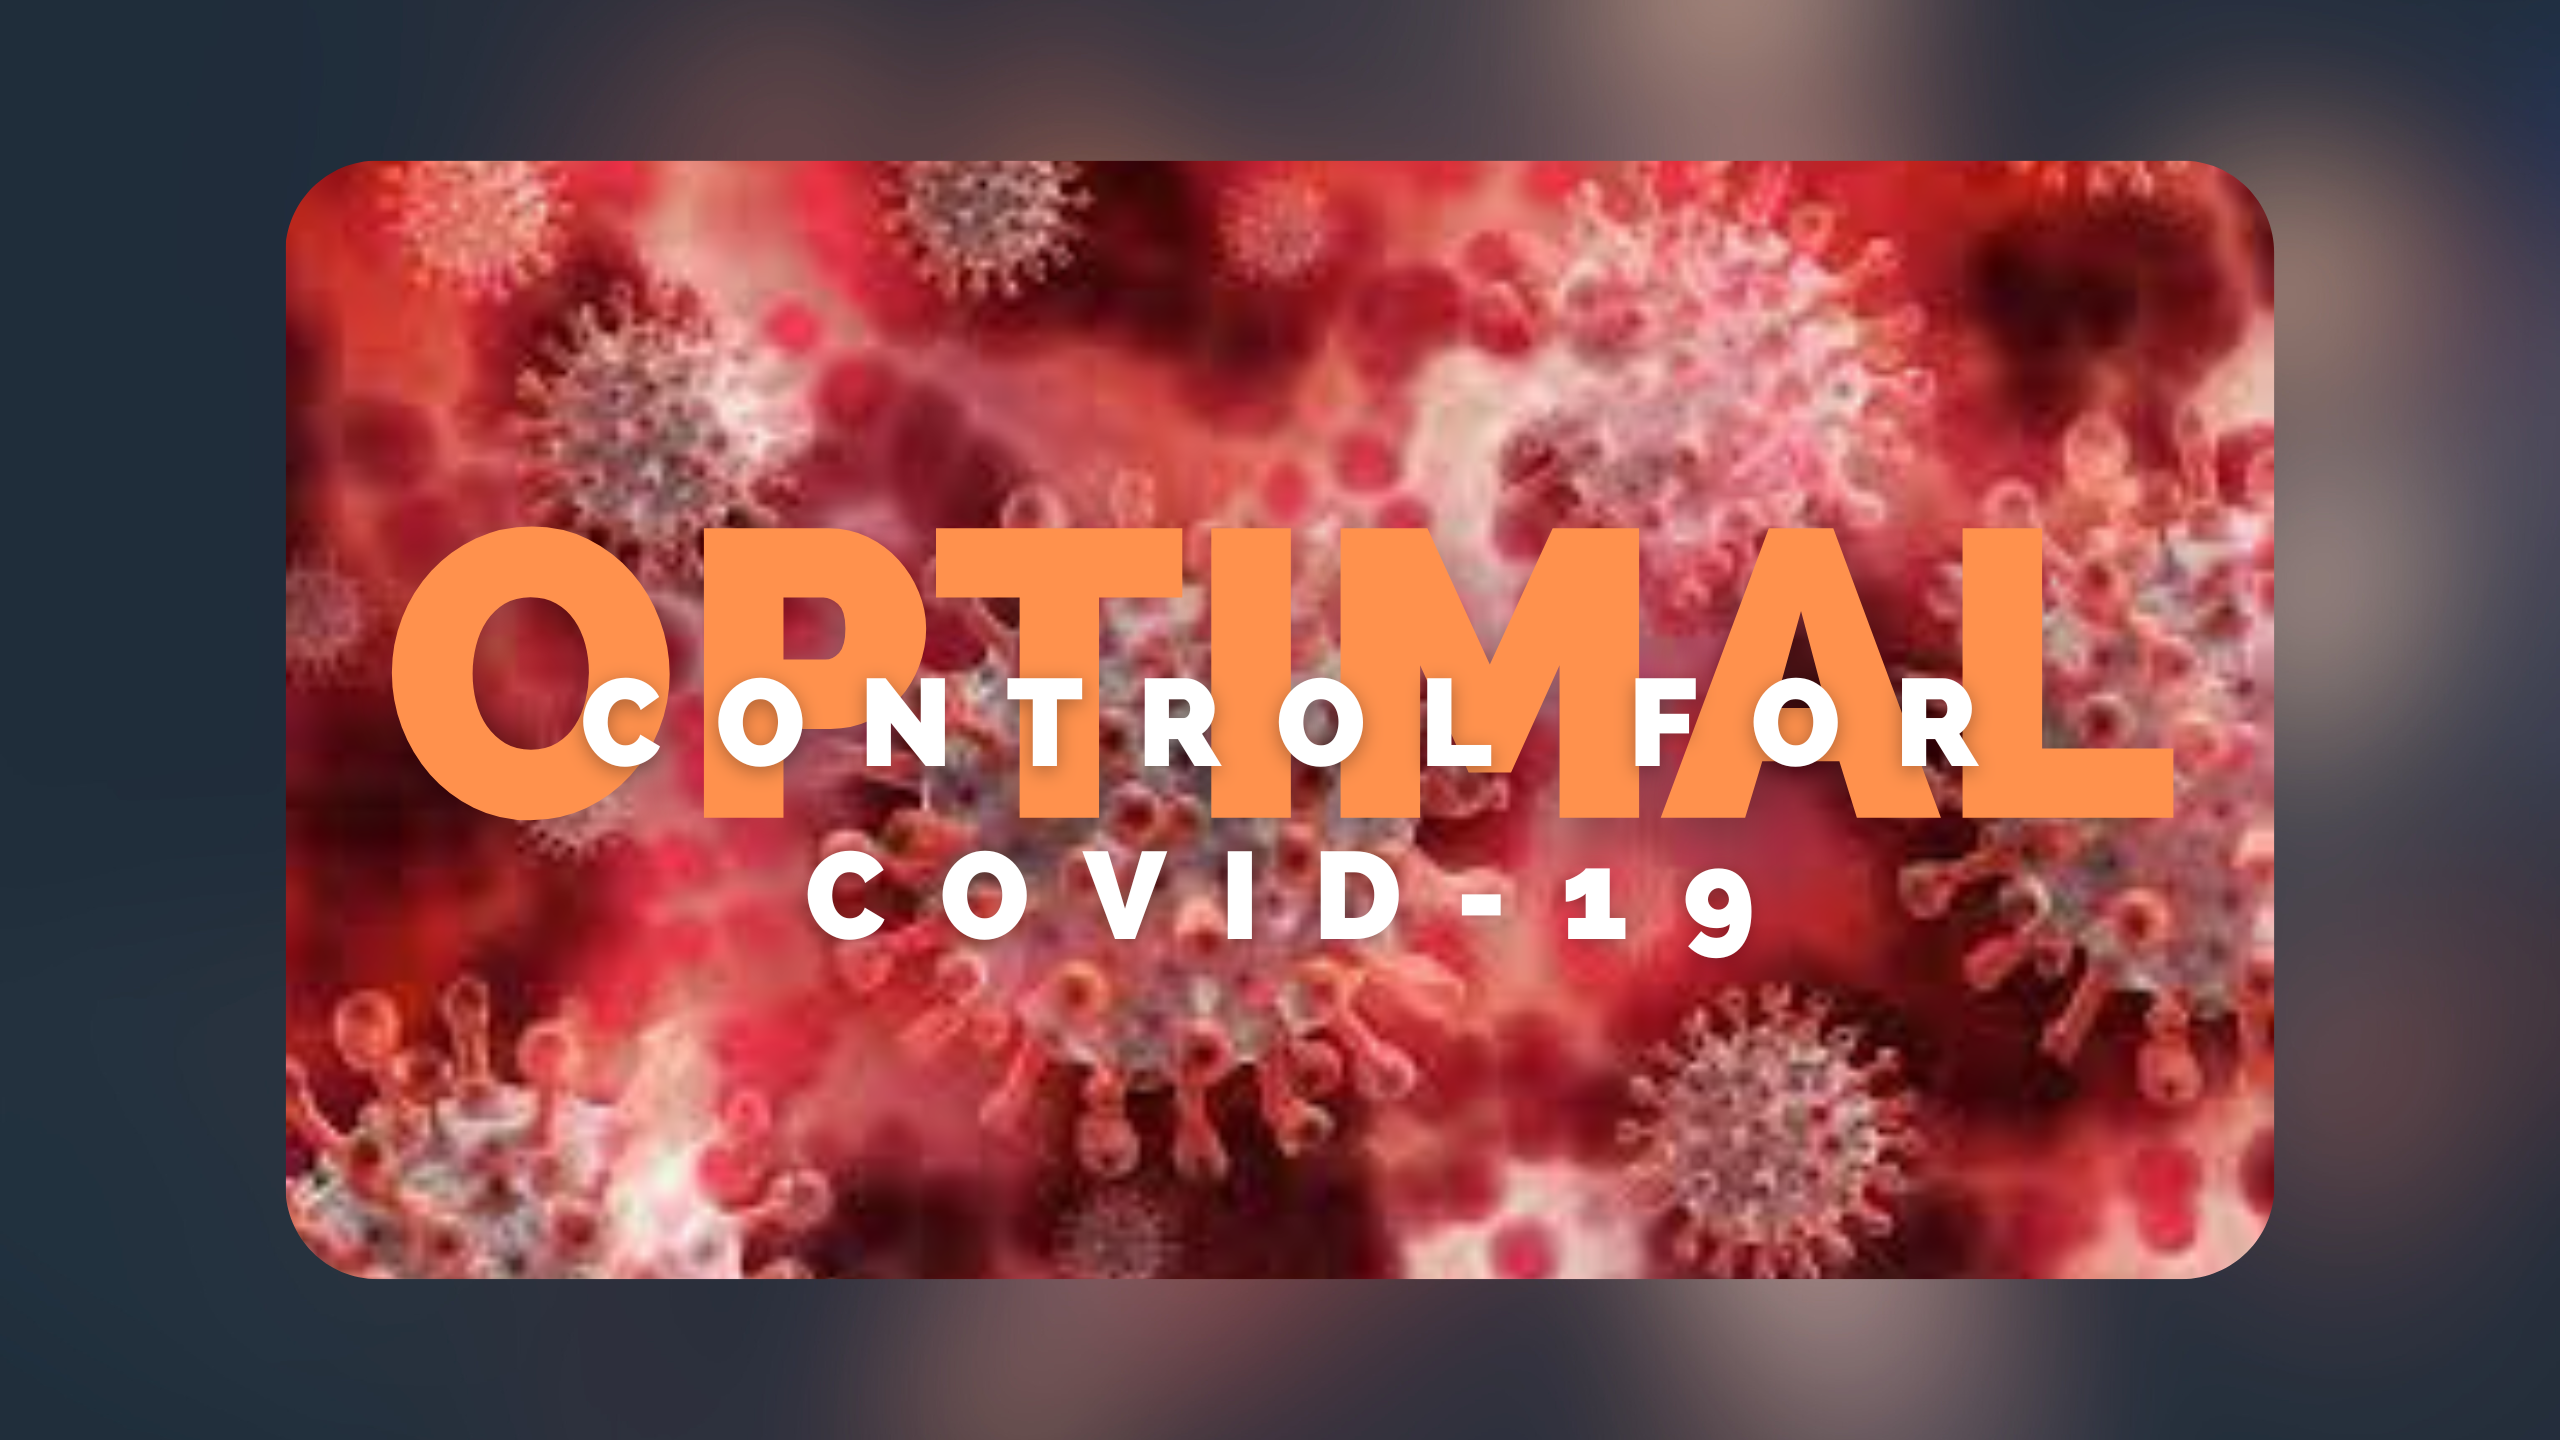


**Copyright:** 
    The analysis in this Notebook employs Covid SEIQ Mathematical models developed by **Jonas Nyador**, **Justice Addae**, and **Kingsley Opoku** at the Mathmods labaratory hosted by the **University of L'aquila** and the **University of Hamburg**.

**References:**
        For more details, please consult the [Jonas Nyador et al., 2021].For more and other selected analysis

**Optimal Control Analysis**

**CONTENT**

* [Introduction](#Introduction)
* [Chapters](#section-two)
    - [Research Objectives](#Research-Objectives)
    - [Compartmental Model](#Compartmental-Model)
    - [Model Equation](#Model-Equation)
    - [Model Parameters](#Model-Parameters)
    - [Model Definition](#Model-Definition)
    - [Global and local Stability](#Global-and-local-Stability)
    - [Sensitivity Analysis](#Sensitivity-Analysis)
    - [Optimal Control](#Optimal-Control)
* [Conclusion](#Conclusion)


# Introduction

In December 2019, a new coronavirus (COVID-19) outbreak caused by severe acute respiratory syndrome of Corona virus 2 (SARS-CoV-2) spread rapidly over the world, affecting a number of countries, including Italy. By April 2020, Italy had a high number of confirmed cases, with 32,785 deaths and 141,981 persons recovering from the sickness. Coronaviruses, a kind of single-stranded RNA virus, are assumed to have originated in bats before migrating to other mammals and infecting humans, causing a variety of respiratory diseases ranging from common colds to more serious lower respiratory tract infections.We want to try mathematical modeling and then optimum control using this.


# Research-Objectives

The research objectives of this study are as follows:

*     To analyze the transmission dynamics of the Corona virus (COVID-19) using mathematical modeling, considering factors such as population demographics, infection rates, and the impact of control measures.

*     To assess the effectiveness of various control strategies, including isolation, quarantine, and other preventive measures, in reducing the transmission rate of the virus.

*     To calculate and evaluate the effective reproduction number (R0) of the virus, which indicates the average number of secondary infections caused by a single infected individual, and determine its impact on the spread of COVID-19.

*     To perform stability and steady state analysis to understand the long-term behavior of the disease dynamics and identify critical points where interventions can be implemented to control the epidemic.

*     To conduct optimal control analysis to predict and suggest the most effective strategies for overcoming the COVID-19 epidemic, taking into account limited resources and economic constraints.

*     To incorporate a vaccination class into the model and use optimal control methods to propose efficient allocation strategies for limited resources to achieve virus eradication.

*     To contribute to the understanding of COVID-19 transmission dynamics and provide valuable insights and recommendations for policymakers, healthcare professionals, and public health authorities in formulating evidence-based strategies for disease detection, control, and prevention.

# Compartmental-Model

Our suggested Corona virus illness epidemic model is an SEIQ model. The whole population is separated into four mutual compartments: **Susceptible (S)**, **Exposed (E)**, **Infected (I)**, and **Quarantine (Q)**. The graphic in Figure 1 depicts the dynamics of corona virus transmission.


# Model-Equation

The mathematical model describing the dynamics of the COVID-19 is expressed as systems of differential equation as follows:

\begin{align*}
\frac{{dS}}{{dt}} &= A - \beta S(t) I(t) - \mu S(t) + cQ(t) \\
\frac{{dE}}{{dt}} &= \beta S(t) I(t) - (\epsilon + \mu + d) E(t) \\
\frac{{dI}}{{dt}} &= \epsilon E(t) - (\alpha + \mu + \sigma) I(t) \\
\frac{{dQ}}{{dt}} &= \sigma I(t) + dE(t) - (\alpha + \mu + c) Q(t)
\end{align*}

where** $S(t)$, $E(t)$, $I(t)$,** and **$Q(t)$** represent the number of susceptible, exposed, infected, and quarantined individuals at time $t$, respectively. The model parameters ($A$, $\beta$, $\mu$, $c$, $\epsilon$, $d$, $\alpha$, $\sigma$) are all positive.

#  Modeling-and-Simulation

**Warnings:** To ensure optimal functionality of the Python files, kindly import all the necessary files before commencing the project. Failure to do so may impede the smooth running of the files and hinder the attainment of desired outcomes. Therefore, it is crucial to import all relevant files before embarking on the project


In [1]:
!pip install numpy
!pip install matplotlib
!pip install scipy


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d

import warnings
warnings.filterwarnings("ignore")

# Model-Parameters



The following is a list of all the model parameters and their initial values based on literature from disease transmission modeling.

\begin{align*}
S & : \text{Susceptible} & 2000 \text{ (Estimated)} \\
E & : \text{Exposed} & 1000 \text{ (Estimated)} \\
I & : \text{Infected} & 70 \text{ (Estimated)} \\
Q & : \text{Quarantine} & 20 \text{ (Estimated)} \\
\alpha & : \text{Death due to the virus} & 0.000015 \text{ (Index Mundi)} \\
\beta & : \text{Rate of transmission} & 0.0006515 \text{ (Giordano et. al. (2020))} \\
c & : \text{Recovery rate} & 0.00017 \text{ (Index Mundi)} \\
\epsilon & : \text{Rate from exposed to infected} & 0.1667 \text{ (Index Mundi)} \\
\sigma & : \text{Rate from infected to quarantine} & 0.50 \text{ (Giordano et. al. (2020))} \\
\mu & : \text{Mortality rate} & 0.00021 \text{ (WHO)} \\
d & : \text{Rate from exposed to quarantine} & 0.050 \text{ Index Mundi }\\
A & : \text{Recruitment rate} & 0.001 \text{ (Index Mundi)}
\end{align*}

Throughout this investigation, this will be used in modeling and simulation.

In [3]:
"""
________________________________________________________________________________
                    Parameters
________________________________________________________________________________
"""
A = 0.001  # Total population
beta = 0.0006515 # Transmission rate
epsilon = 0.1667 # Incubation rate
alpha = 0.000015 # Recovery rate
sigma = 0.50  # Treatment rate
mu = 0.00021  # Natural mortality rate
d = 0.050 # Disease-induced mortality rate
c = 0.00017 # Cost of vaccination
T = 100  # Time horizon

"""
________________________________________________________________________________
                    Initial Conditions
================================================================================
"""
S0 = 2000
E0 = 1000
I0 = 70
Q0 = 20


# Model-Definition

In [4]:
def SIR(t, y):
    """
    _________________________________________________
                SEIQ MODEL FOR COVID 19 
    =================================================
    Args:
        - t : time
        - y : intial states 
    Returns:
        - dSdt, dEdt, dIdt, dQdt
    =================================================
    """
    S, E, I, Q = y

    # System dynamics
    dSdt = A - beta * S * I - mu * S + c * Q
    dEdt = beta * S * I - (epsilon + mu + d) * E
    dIdt = epsilon * E - (alpha + mu + sigma) * I
    dQdt = sigma * I + d * E - (alpha + mu + c) * Q

    return [dSdt, dEdt, dIdt, dQdt]

We going to solve the Intial Value problem form time equal to zero to the final time T

In [5]:
t_span = (0, T)

Solve the **Ordinary Differential Equation** using the solve intial Value problem model.

In [6]:
sol = solve_ivp(SIR, t_span, [S0, E0, I0, Q0], dense_output=True)

**Extract the solution at higher resolutions**

In [7]:
t_interp = np.linspace(0, T, 10000)
y_interp = sol.sol(t_interp)

In [8]:
y_interp

array([[2.00000000e+03, 1.99907530e+03, 1.99813401e+03, ...,
        1.39081199e+02, 1.39085818e+02, 1.39090437e+02],
       [1.00000000e+03, 9.98752580e+02, 9.97524453e+02, ...,
        1.06492452e-04, 1.06310274e-04, 1.06128392e-04],
       [7.00000000e+01, 7.13126447e+01, 7.26166805e+01, ...,
        5.36888222e-05, 5.35977758e-05, 5.35069283e-05],
       [2.00000000e+01, 2.08529772e+01, 2.17118743e+01, ...,
        2.88280722e+03, 2.88279583e+03, 2.88278445e+03]], shape=(4, 10000))

Interpolate the solution of **Suspectable, Exposed, Infected, Quarantine** using a smooth quanrantine curve using the higher resolution solutions.

In [9]:
f_S = interp1d(t_interp, y_interp[0], kind='cubic')
f_E = interp1d(t_interp, y_interp[1], kind='cubic')
f_I = interp1d(t_interp, y_interp[2], kind='cubic')
f_Q = interp1d(t_interp, y_interp[3], kind='cubic')

Graphical represent the solution of **Suspectable, Exposed, Infected, Quarantine** using a smooth quanrantine curve using interpolated curves.

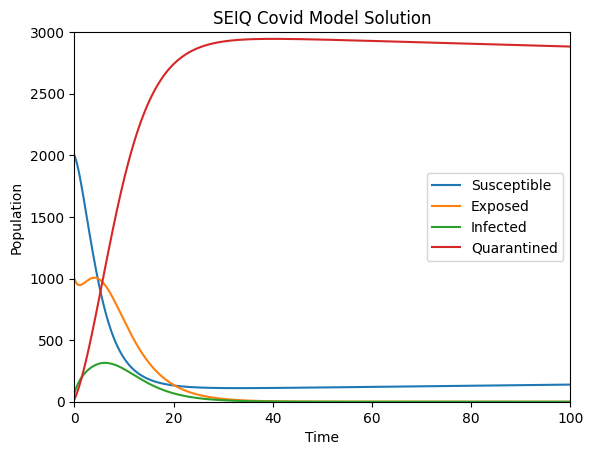

In [10]:
# Plot the interpolated solution curves
plt.plot(t_interp, f_S(t_interp), label='Susceptible')
plt.plot(t_interp, f_E(t_interp), label='Exposed')
plt.plot(t_interp, f_I(t_interp), label='Infected')
plt.plot(t_interp, f_Q(t_interp), label='Quarantined')
plt.axis([0, 100, 0, 3000])
plt.xlabel('Time')
plt.ylabel('Population')
plt.title('SEIQ Covid Model Solution')
plt.legend()
plt.grid(False)
plt.show()

# Global-and-local-Stability

**Local Stability**

In [11]:
# Check Local stability (if all eigenvalues have negative real parts, the equilibrium is globally stable
# Jacobian matrix
def jacobian(S, E, I, Q):
    return np.array([[-beta * I - mu, 0, -beta * S, 0],
                     [beta * I, -epsilon - mu - d, beta * S, 0],
                     [0, epsilon, -alpha - mu - sigma, 0],
                     [0, d, sigma, -alpha - mu]])

# Compute eigenvalues of the Jacobian at equilibrium points
equilibrium_points = [(sol.y[0][-1], sol.y[1][-1], sol.y[2][-1], sol.y[3][-1])]
eigenvalues = np.linalg.eigvals(jacobian(*equilibrium_points[0]))

# Check global stability (if all eigenvalues have negative real parts, the equilibrium is globally stable)
is_locally_stable = np.all(np.real(eigenvalues) < 0)
print("Local stability:", is_locally_stable)

Local stability: True


# Check Global stability 
Lyapunov theorem, the DFE of the Covid-19 virus is globally asymptotically stable.

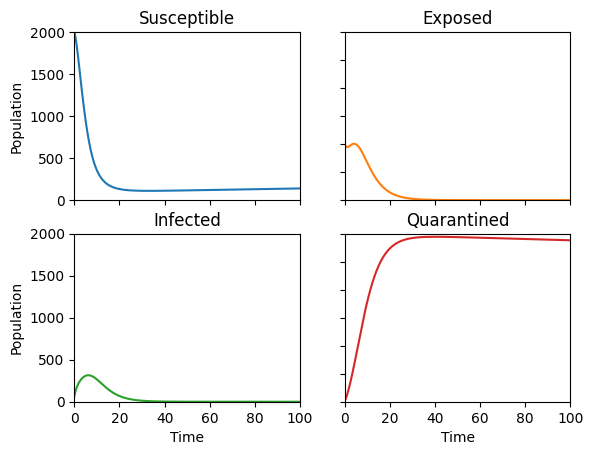

In [12]:
fig, axs = plt.subplots(2, 2)
axs[0, 0].plot(t_interp, f_S(t_interp), 'tab:blue')
axs[0, 0].set_title('Susceptible')
axs[0,0].axis([0, 100, 0, 2000])

axs[0, 1].plot(t_interp, f_E(t_interp), 'tab:orange')
axs[0, 1].set_title('Exposed')
axs[0,1].axis([0, 100, 0, 3000])

axs[1, 0].plot(t_interp, f_I(t_interp), 'tab:green')
axs[1, 0].set_title('Infected')
axs[1,0].axis([0, 100, 0, 2000])

axs[1, 1].plot(t_interp, f_Q(t_interp), 'tab:red')
axs[1, 1].set_title('Quarantined')
axs[1, 1].axis([0, 100, 0, 3000])

for ax in axs.flat:
    ax.set(xlabel='Time', ylabel='Population')

# Hide x labels and tick labels for top plots and y ticks for right plots.
for ax in axs.flat:
    ax.label_outer()

# Sensitivity-Analysis

In other to understand how best to reduce infection due to the Covid-19 infection, it is important to know the different factors responsible for the infection be varied.

In [ ]:
# Variation parameters
infected_cases = np.logspace(1, 3, 5)  # Vary the initial infected cases
total_population = np.logspace(3, 4, 5)  # Vary the total population
infectious_rate = np.logspace(-4, -3, 5)  # Vary the infectious rate (beta)
quarantine_rate = np.logspace(-5, -4, 5)  # Vary the quarantine rate

# Plotting colors
colors = plt.cm.viridis(np.linspace(0, 1, len(infected_cases)))

# Perform the variation analysis
for i, infected in enumerate(infected_cases):
    for j, population in enumerate(total_population):
        for k, beta_value in enumerate(infectious_rate):
            for l, quarantine_value in enumerate(quarantine_rate):
                # Update initial conditions and parameters
                I0_varied = infected
                A_varied = population
                beta_varied = beta_value
                sigma_varied = quarantine_value

                # Solve the ODE system
                sol = solve_ivp(SIR, t_span, [S0, E0, I0_varied, Q0], dense_output=True)

                # Extract the solution at higher resolution
                t_interp = np.linspace(0, T, 10000)
                y_interp = sol.sol(t_interp)

                # Interpolate the solution curves for smoother plotting
                f_S = interp1d(t_interp, y_interp[0], kind='cubic')
                f_E = interp1d(t_interp, y_interp[1], kind='cubic')
                f_I = interp1d(t_interp, y_interp[2], kind='cubic')
                f_Q = interp1d(t_interp, y_interp[3], kind='cubic')
                
                # Plot the infected population variation
                plt.subplot(2, 2, 1)
                plt.plot(t_interp, f_S(t_interp), color=plt.cm.viridis(i/len(infected_cases)))
                plt.title("Susceptible")
                plt.ylabel("Population")
                plt.subplot(2, 2, 2)
                plt.plot(t_interp, f_E(t_interp), color=plt.cm.viridis(i/len(infected_cases)))
                plt.title("Exposed")
                plt.subplot(2, 2, 3)
                plt.plot(t_interp, f_I(t_interp), color=plt.cm.viridis(i/len(infected_cases)))
                plt.title("Infection")
                plt.ylabel("Population")
                plt.xlabel("Time")
                plt.subplot(2, 2, 4)
                plt.plot(t_interp, f_Q(t_interp), color=plt.cm.viridis(i/len(infected_cases)))
                plt.title("Quarantine")
                plt.xlabel("Time")
                
                # Adjust the layout
                plt.tight_layout()

According to the analysis, the transmission rate, rate of infected individuals to quarantine rate are identified as the most sensitive parameters. This suggests that changes in these parameters have a significant impact on the dynamics of the Covid-19 pandemic model.

Furthermore, the analysis indicates that individuals who recover from Covid-19 have no risk of becoming susceptible again. This finding suggests that immunity is acquired after recovery, and individuals are protected from reinfection.

However, it is noted that although the rate of transmission of the Covid-19 virus is sensitive, its impact is significantly less compared to the rate of death due to the virus. This implies that interventions targeting the reduction of transmission may have a relatively smaller effect on the overall outcome compared to interventions aimed at reducing mortality rates.

It is important to note that these conclusions are based on the specific analysis conducted and the assumptions made in the Covid-19 pandemic model. Real-world dynamics and factors may vary, and additional research and analysis are needed to further understand and validate these findings.

# Optimal-Control

For optimal control analysis, we apply Pontragin Maximum Principle. In this paper, we consider optimal pairs {Vaccination and Treatment Strategies} that minimize the infection and minimize transmission, at the same time minimizing cost (Eihab B. M. et al)

**Remark**
1. The Hamiltonian function H is strongly convex in the control variables.
2. The right-hand sides of the state and co-state equations are Lipschitz continuous.
3. The set of the admissible controls U is convex

In this section we consider the above optimal control theory with consideration of its applicability. We discuss the discretization of the optimal control and present the numerical result obtained through our simulation.

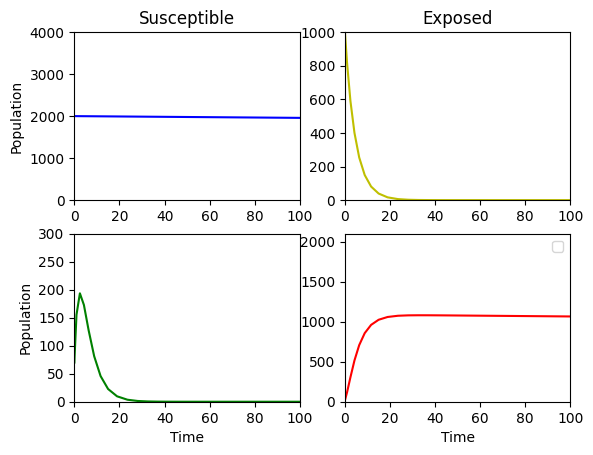

In [ ]:
# Control bounds
c_min = 0.000
c_max = 1.000

# Define the SIR dynamics
def SIR(t, y, c):
    S, E, I, Q = y

    # System dynamics
    dSdt = A - c * Q - mu * S
    dEdt = c * Q - (epsilon + mu + d) * E
    dIdt = epsilon * E - (alpha + mu + sigma) * I
    dQdt = sigma * I + d * E - (alpha + mu + c) * Q

    return [dSdt, dEdt, dIdt, dQdt]

# Define the Hamiltonian function
def hamiltonian(t, y, p, c):
    S, E, I, Q = y
    pS, pE, pI, pQ = p

    H = - pS * (A - c * Q - mu * S) \
        - pE * (c * Q - (epsilon + mu + d) * E) \
        - pI * (epsilon * E - (alpha + mu + sigma) * I) \
        - pQ * (sigma * I + d * E - (alpha + mu + c) * Q)

    return H

# Define the optimal control problem
def optimal_control(t, y, p):
    S, E, I, Q = y
    pS, pE, pI, pQ = p

    # Calculate the optimal control
    c_opt = np.clip((pQ - pS) / (2 * c), c_min, c_max)

    return c_opt

# Define the ODE system with optimal control
def ode_system(t, y):
    S, E, I, Q = y

    # Solve for the adjoint variables using backward integration
    sol_adj = solve_ivp(lambda t, p: [-hamiltonian(t, y, p, optimal_control(t, y, p))], [T, t], [-1, -1, -1, -1])

    pS, pE, pI, pQ = sol_adj.y[:, 0]

    # Calculate the optimal control
    c_opt = optimal_control(t, y, [pS, pE, pI, pQ])

    return SIR(t, y, c_opt)

# Solve the optimal control problem
sol = solve_ivp(ode_system, [0, T], [S0, E0, I0, Q0])

# Extract the solution
t = sol.t
S = sol.y[0]
E = sol.y[1]
I = sol.y[2]
Q = sol.y[3]

# Plot the solution

plt.subplot(2, 2, 1)
plt.plot(t, S, label='Susceptible',  scalex=True, scaley=True, color ="b")
plt.axis([0, 100, 0, 4000])
plt.title("Susceptible")
plt.ylabel('Population')

plt.subplot(2, 2, 2)
plt.plot(t, E, label='Exposed',  scalex=True, scaley=True, color ="y")
plt.title("Exposed")
plt.axis([0, 100, 0, 1000])

plt.subplot(2, 2, 3)
plt.plot(t, I, label='Infected',  scalex=True, scaley=True, color ="g")
plt.axis([0, 100, 0, 300])
plt.ylabel('Population')
plt.xlabel('Time')

plt.subplot(2, 2, 4)
plt.plot(t, Q, scalex=True, scaley=True, color ="r")
plt.axis([0, 100, 0, 2100])
plt.xlabel('Time')

plt.legend()
plt.grid(False)
plt.show()

Figure represent the different dynamics of the Susceptible, Exposed, Infective and Quarantine population for different control measures. The blue color represent the susceptible population when the is vaccination. Red, Gold and Magnet represent the quarantine, Infected, and Exposed population respectively whiles the yellow and green represent the respective control parameters.

Text(0.5, 1.0, 'Optimal Cost of Vaccination in SIR Model')

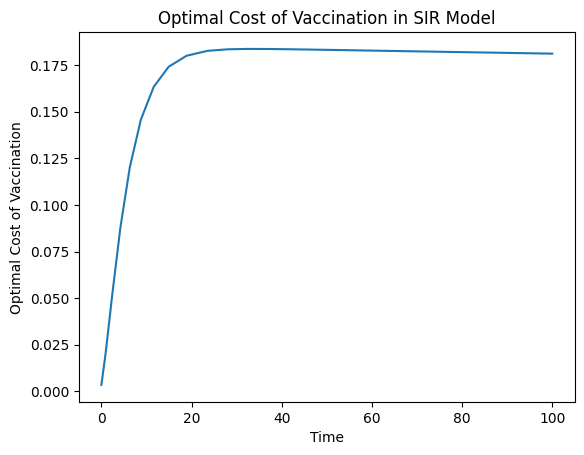

In [ ]:
# Calculate the optimal cost of vaccination
cost_vaccination = c * Q

# Plot the optimal cost of vaccination
plt.plot(t, cost_vaccination)
plt.xlabel('Time')
plt.ylabel('Optimal Cost of Vaccination')
plt.title('Optimal Cost of Vaccination in SIR Model')

# Conclusion

In this paper, we considered formulating the mathematical model base on the SEIQ formulation. A disease-free equilibrium solution was estimated and both the local and Global stability of the model formulated was performed base on Routh criterion and lypunov theorem, respectively. A sensitivity analysis was performed to see the parameter influence on the transmission of COVID-19. We considered an optimal control problem for SEIQ model. The main idea developed here was to formulate an optimal control problem in order to search among the available strategies, the
most efficient strategies to reduce Susceptibility, Expose and Infected population to a minimum level while optimizing the cost by deploying preventive measures (vaccination and treatment) to control the disease progression. Then we formulated the objective function of the optimal control problem. We discuss the existence of the optimal control and then derived the first order necessary condition for the optimal control through constructing the Hamiltonian and using the Pontryagin’s maximum principle to achieve our aim. Finally, we performed a numerical simulation to corroborate the theoretical result obtained, showing that the model is relevant for controlling the spread of the Corona virus.